In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

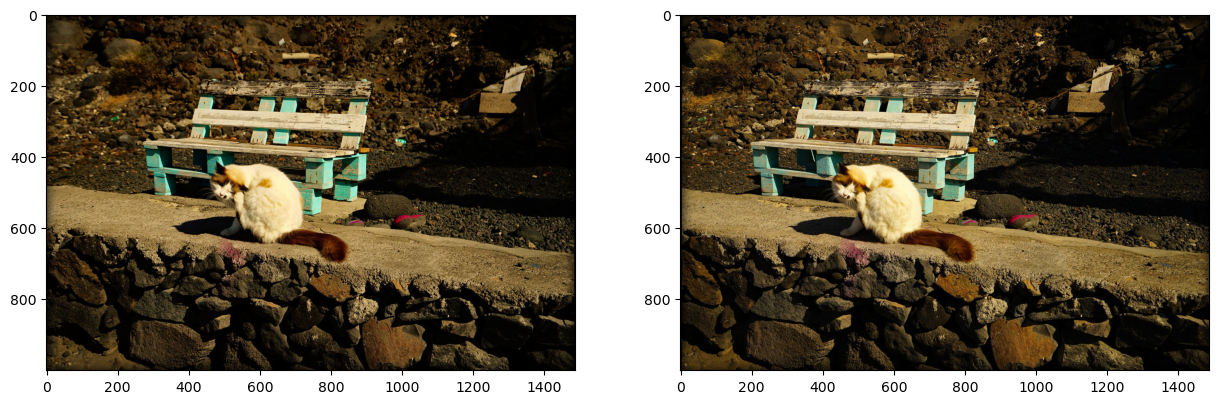

In [3]:
cat_l = cv2.cvtColor(cv2.imread("images/cat_l.jpg"), cv2.COLOR_BGR2RGB)
cat_r = cv2.cvtColor(cv2.imread("images/cat_r.jpg"), cv2.COLOR_BGR2RGB)


fig, ax = plt.subplots(1,2, figsize=(15,10))
ax[0].imshow(cat_l)
ax[1].imshow(cat_r)

CPU times: user 6.11 ms, sys: 3.74 ms, total: 9.86 ms
Wall time: 8.99 ms


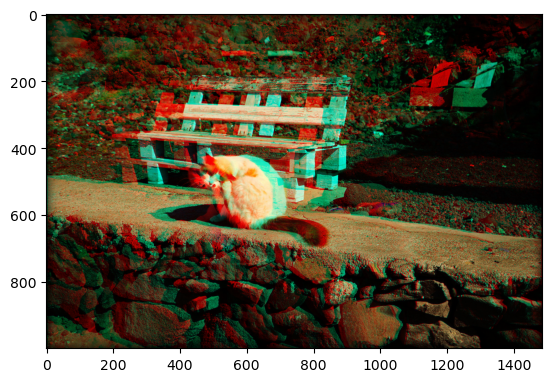

In [4]:
%%time
def anaglyphe_for (img_l, img_r):
    result = np.copy(img_r)

    img_shape = img_l.shape

    for j in range (img_shape[0]):
        for i in range (img_shape[1]):
            result[j][i][0] = img_l[j][i][0]
            result[j][i][1] = img_r[j][i][1]
            result[j][i][2] = img_r[j][i][2]
    return result


def anaglyphe_np(image_d, image_g):
    img = np.concatenate((image_g[:, :, 0:1], image_d[:, :, 1:3]), axis=2)
    return img

# plt.imshow(anaglyphe_for(cat_l, cat_r))
plt.imshow(anaglyphe_np(cat_l, cat_r))


In [5]:
# def mean_difference(img_l, img_r, block_size, current_coord):
#     result = 0
#     for i in range(N):
#         for j in range(N):
#             result = np.abs(img_l[i + current_coord, j + current_coord, 0] - img_r[i + current_coord,j + current_coord,0])
#     result = (1/(block_size**2)) * result
#     return result

# def mean_squared_error(img_l, img_r, block_size, current_coord):
#     result = 0
#     for i in range(N):
#         for j in range(N):
#             result = (img_l[i + current_coord, j + current_coord, 0] - img_r[i + current_coord,j + current_coord,0])**2
#     result = (1/(block_size**2)) * result
#     return result

# def psnr(img_l, img_r, block_size, current_coord):
#     result = 10 * np.log10((255**2)/ mean_squared_error(img_l, img_r, block_size, current_coord))

# def disparity (img_l, img_r, block_size):
#     result = np.zeros_like(img)
    
    

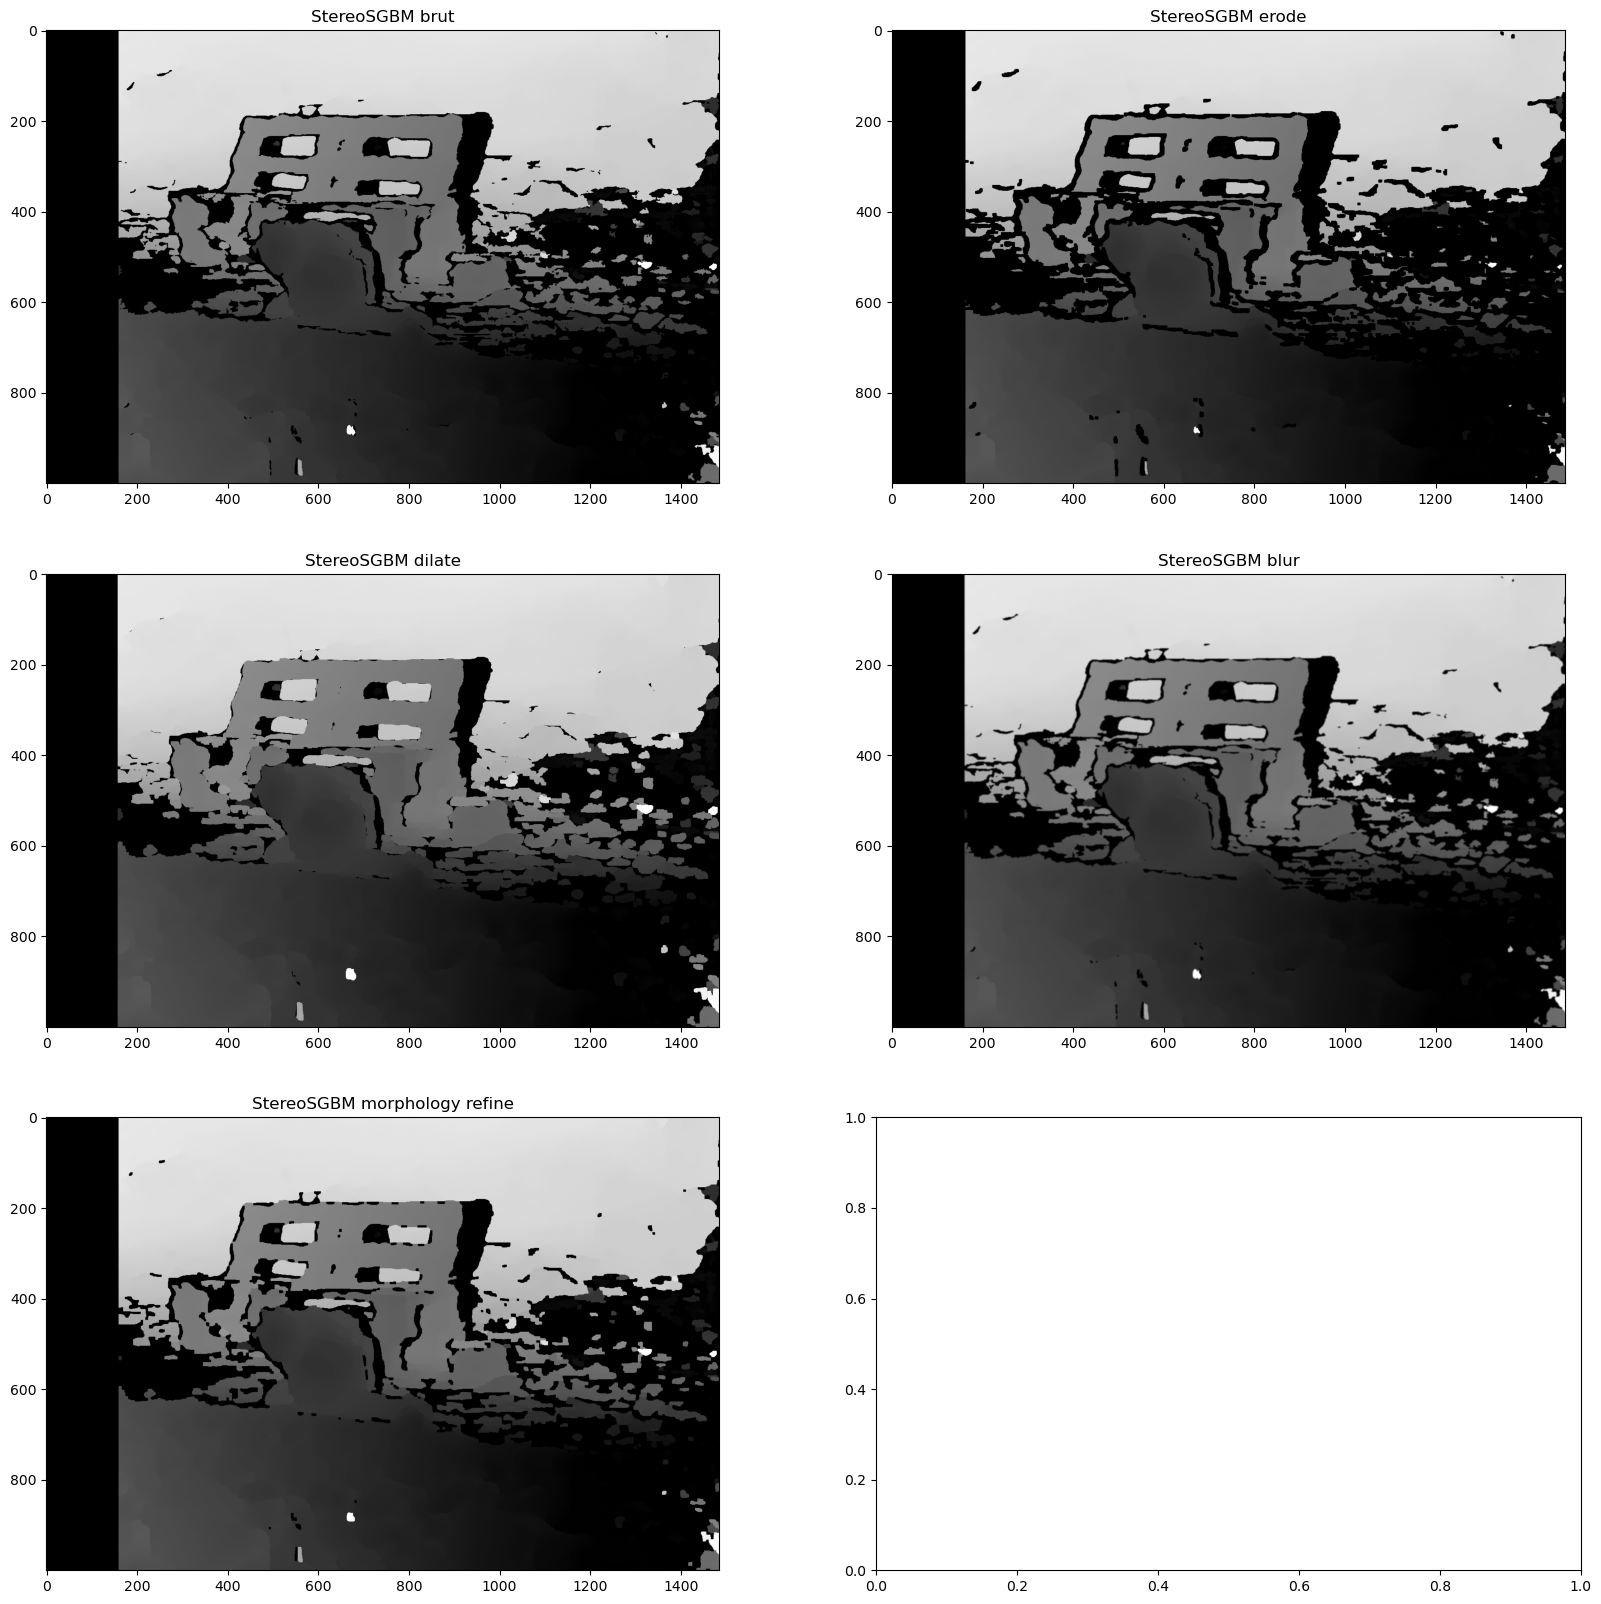

In [6]:
MIN_DISPARITY = 0
NUM_DISPARITIES = 160
BLOCK_SIZE = 19
P1 = 8*1*BLOCK_SIZE*BLOCK_SIZE
P2 = 32*1*BLOCK_SIZE*BLOCK_SIZE
UNIQUENESS_RATIO = 0
SPECKLE_SIZE = 100
SPECKLE_RANGE = 2

stereo = cv2.StereoSGBM.create(
    minDisparity = 0,
    numDisparities = NUM_DISPARITIES,
    blockSize = BLOCK_SIZE,
	P1 = P1,
	P2 = P2,
	disp12MaxDiff = 0,
	preFilterCap = 0,
	uniquenessRatio = UNIQUENESS_RATIO,
	speckleWindowSize = SPECKLE_SIZE,
	speckleRange = SPECKLE_RANGE,
)
    
def disparity_bm (img_l, img_r, stereo):
    disparity = stereo.compute(img_l, img_r)
    return disparity

img_l_gray = cv2.imread("images/cat_l.jpg", cv2.IMREAD_GRAYSCALE)
img_r_gray = cv2.imread("images/cat_r.jpg", cv2.IMREAD_GRAYSCALE)
# img_l_gray = cv2.imread("images/head_l.jpg", cv2.IMREAD_GRAYSCALE)
# img_r_gray = cv2.imread("images/head_r.jpg", cv2.IMREAD_GRAYSCALE)

disparity = disparity_bm(img_l_gray, img_r_gray, stereo)

kernel = np.ones((5, 5), np.uint8)
img_gray_e  = cv2.erode(disparity , kernel)
img_gray_d  = cv2.dilate(disparity , kernel)
img_gray_b  = cv2.GaussianBlur(disparity, (5,5), 0)

img_gray_mo  = cv2.morphologyEx(disparity, cv2.MORPH_OPEN, kernel)
img_gray_mc  = cv2.morphologyEx(disparity, cv2.MORPH_CLOSE, kernel)
img_gray_mr  = cv2.morphologyEx(img_gray_mc, cv2.MORPH_OPEN, kernel)


fig, ax = plt.subplots(3,2, figsize=(20,20))
ax[0, 0].imshow(disparity, 'gray')
ax[0, 0].set_title("StereoSGBM brut")
ax[0, 1].imshow(img_gray_e, 'gray')
ax[0, 1].set_title("StereoSGBM erode")
ax[1, 0].imshow(img_gray_d, 'gray')
ax[1, 0].set_title("StereoSGBM dilate")
ax[1, 1].imshow(img_gray_b, 'gray')
ax[1, 1].set_title("StereoSGBM blur")
ax[2, 0].imshow(img_gray_mr, 'gray')
ax[2, 0].set_title("StereoSGBM morphology refine")
plt.show()

error: OpenCV(4.10.0) ./modules/imgproc/src/segmentation.cpp:161: error: (-215:Assertion failed) src.type() == CV_8UC3 && dst.type() == CV_32SC1 in function 'watershed'


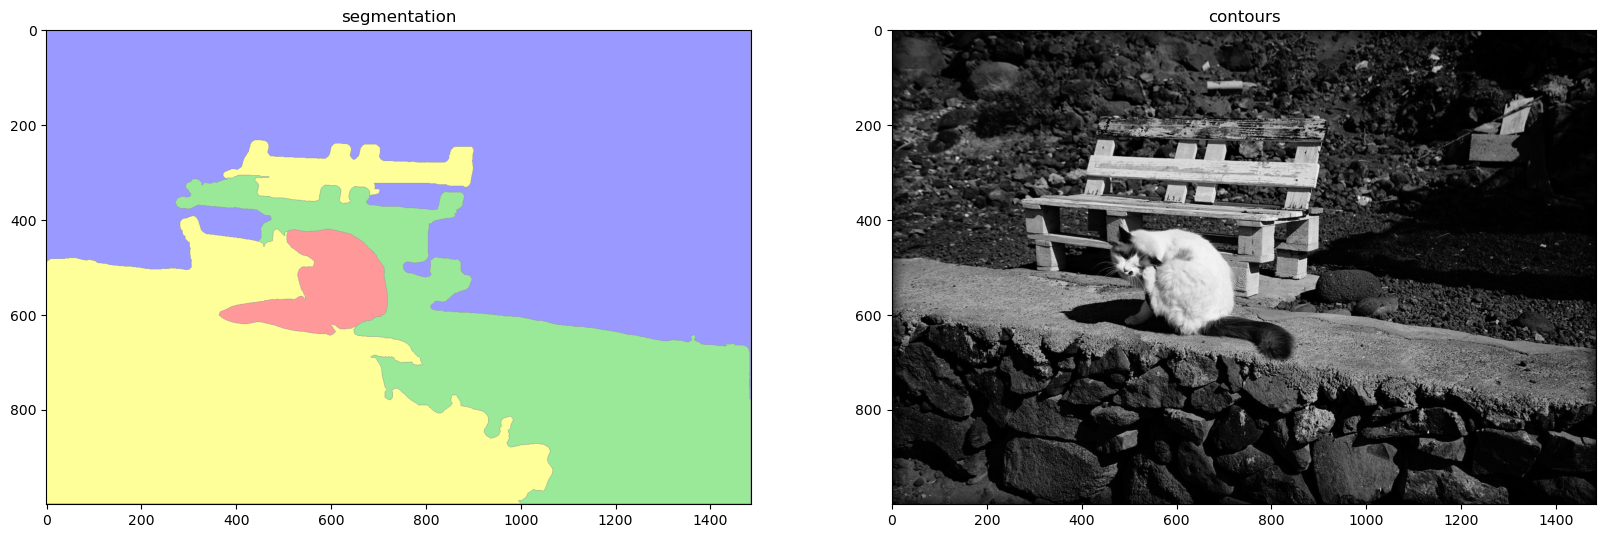

In [ ]:
cat_rgb = cv2.cvtColor(cv2.imread("images/cat_l.jpg"), cv2.COLOR_BGR2RGB)
cat_gray = cv2.imread("images/cat_l.jpg", cv2.IMREAD_GRAYSCALE)
# disparity = np.uint8(img_gray_mr)
# disparity = np.uint8(disparity)
disparity = np.uint16(img_gray_d)
 
def segmentation_hist(img):
    plt.hist(img.ravel(),bins=180,range=(0, 255))
    plt.show()

def segmentation_border(img, img_rgb, plot):    
    # img = cv2.GaussianBlur(img, (5,5), 0)
    laplacian = cv2.Laplacian(img,cv2.CV_64F)
    sobelx = cv2.Sobel(img,cv2.CV_64F,1,0,ksize=5)
    sobely = cv2.Sobel(img,cv2.CV_64F,0,1,ksize=5)
    
    abs_laplacian = np.absolute(laplacian)
    abs_sobelx = np.absolute(sobelx)
    abs_sobely = np.absolute(sobely)
    
    marker = abs_sobelx + abs_sobely
    
    img = [abs_laplacian, marker]
    close = [1, 1]
    for i in range (2):
        blur = cv2.GaussianBlur(img[i],(5,5),0)
        blur = np.uint8(blur)
        ret, thresh = cv2.threshold(blur,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
        close[i] = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations = 2)

    contours, hierarchy = cv2.findContours(close[0], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_segmentee = img_rgb.copy()
    cv2.drawContours(img_segmentee, contours, -1, (0, 0, 255), 2)
    
    if plot:
        _, b_plot = plt.subplots(5,2, figsize=(20,20))
        
        b_plot[0, 0].imshow(laplacian, 'gray')
        b_plot[0, 0].set_title("laplacian")
        b_plot[0, 1].imshow(sobelx, 'gray')
        b_plot[0, 1].set_title("sobel X")
        b_plot[1, 0].imshow(sobely, 'gray')
        b_plot[1, 0].set_title("sobel Y")
        b_plot[1, 1].imshow(abs_laplacian, 'gray')
        b_plot[1, 1].set_title("abs laplacian")
        b_plot[2, 0].imshow(abs_sobelx, 'gray')
        b_plot[2, 0].set_title("abs sobel X")
        b_plot[2, 1].imshow(abs_sobely, 'gray')
        b_plot[2, 1].set_title("abs sobel Y")
        b_plot[3, 0].imshow(marker, 'gray')
        b_plot[3, 0].set_title("marker")
        b_plot[3, 1].imshow(close[0], 'gray')
        b_plot[3, 1].set_title("close laplacian")
        b_plot[4, 0].imshow(close[1], 'gray')
        b_plot[4, 0].set_title("close marker")
        b_plot[4, 1].imshow(img_segmentee)
        b_plot[4, 1].set_title("contours")

def segmentation_watershed(img, img_gray, param):
    blur = cv2.medianBlur(img_gray, param["blur"])
    
    gray_thresh = [45,143,215]
    classes = np.digitize(blur, gray_thresh)
    
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, param["morph_kernel"])
    markers = np.zeros(blur.shape, dtype=np.int32)

    for k in range(4):
        binary = np.uint8(classes == k) * 255
        opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=2)

        dist = cv2.distanceTransform(opened, cv2.DIST_L2, 5)
        _, sure_fg = cv2.threshold(dist, param["dist_threshold"] * dist.max(), 255, 0)

        markers[sure_fg == 255] = k + 1

    img_bgr = cv2.cvtColor(blur, cv2.COLOR_GRAY2BGR)
    markers = cv2.watershed(img_bgr,markers)

    colors = [
        [0, 0, 255],
        [0, 200, 0],
        [255, 255, 0],
        [255, 0, 0],
    ]
    
    h, w = markers.shape
    segmentation = np.zeros((h, w, 3), dtype=np.uint8) # arrière-plan noir

    for i in range(4):
        segmentation[markers == i + 1] = colors[i]

    segmentation[markers == -1] = [0, 0, 0]
    
    if param["plot"] :
        _, ws_plot = plt.subplots(1,2, figsize=(20,20))
        # ws_plot[0, 0].imshow(img)
        ws_plot[0].imshow(segmentation, alpha=0.4)
        ws_plot[0].set_title("segmentation")
        ws_plot[1].imshow(img_gray, 'gray')
        ws_plot[1].set_title("contours")
        
    return img, markers
    

# segmentation_hist(cat_rgb)
# segmentation_border(cat_gray, cat_rgb, True)
watershed_parameters = {"blur" : 17, "morph_kernel" : (15,15), "dist_threshold" : 0.9, "plot" : True}
res, markers = segmentation_watershed(cat_rgb, cat_gray, watershed_parameters)
# watershed_parameters = {"blur" : 1, "morph_kernel" : (3,3), "dist_threshold" : 0.7, "plot" : True}
# res, markers = segmentation_watershed(cat_rgb, disparity, watershed_parameters)

plt.show()
